**Importing Packages**

In [1]:
import pandas as pd
import numpy as np

import missingno as msno
import matplotlib.pyplot as plt

import seaborn as sns

## **1. Combining Dataset**

In [2]:
df_met = pd.read_csv("datasets/Meteorologi_2024-2026.csv") # Hourly
df_air = pd.read_csv("datasets/ISPU_2024-2025.csv") # Daily

(1) We first must clean `stasiun_pengamatan` in both dataset so aggregation and grouping are clean

In [3]:
def clean_station_name(name):
    if pd.isna(name):
        return np.nan

    name = str(name).strip().upper()

    if 'DKI1' in name or 'BUNDARAN' in name or 'BUNDERAN' in name or 'HI' in name:
        return 'DKI1_BUNDARAN_HI'
    elif 'DKI2' in name or 'KELAPA GADING' in name:
        return 'DKI2_KELAPA_GADING'
    elif 'DKI3' in name or 'JAGAKARSA' in name:
        return 'DKI3_JAGAKARSA'
    elif 'DKI4' in name or 'LUBANG BUAYA' in name:
        return 'DKI4_LUBANG_BUAYA'
    elif 'DKI5' in name or 'KEBON' in name or 'KEBUN' in name or 'JERUK' in name:
        return 'DKI5_KEBON_JERUK'
    return name

df_air['clean_station'] = df_air['stasiun'].apply(clean_station_name)
df_met['clean_station'] = df_met['stasiun_pengamatan'].apply(clean_station_name)

# Sanity Checks
print(f"=== AQI Dataset ===\n{df_air["clean_station"].value_counts(dropna=False)}")
print(f"\n=== Meteorologi Dataset ===\n{df_met["clean_station"].value_counts(dropna=False)}")


=== AQI Dataset ===
clean_station
DKI5_KEBON_JERUK      701
DKI1_BUNDARAN_HI      700
DKI2_KELAPA_GADING    700
DKI4_LUBANG_BUAYA     700
DKI3_JAGAKARSA        700
Name: count, dtype: int64

=== Meteorologi Dataset ===
clean_station
DKI5_KEBON_JERUK      44986
DKI1_BUNDARAN_HI      44780
DKI2_KELAPA_GADING    44754
DKI4_LUBANG_BUAYA     44668
DKI3_JAGAKARSA        44621
Name: count, dtype: int64


(2) We then aggregate `Meteorologi Dataset` to make it daily so it can be merged with `AQI Dataset`
The reasoning for each numerical features are as follow: <br>
| Column | Daily Aggregation | Output Feature(s) | Reasoning | Basis |
|---|---|---|---|---|
| `periode_data`, `tanggal` | None (combine into a date key) | `date` | Date components, not measurements. | Parsed with `pd.to_datetime` from `YYYYMM` + day. |
| `rain` | **sum**, plus `max`, count of rainy hours, and wet-day flag | `rain_sum`, `rain_max_hourly`, `rain_hours`, `is_wet_day` | Rainfall is an accumulation, so the daily total is the sum of hourly amounts. A mean would understate it by roughly 24x. | Cumulative quantity. Wet-day threshold of ≥ 1 mm follows the WMO/ETCCDI convention. |
| `grad` | **mean**, **sum** (converted to MJ/m²/day), and `max` | `grad_mean`, `grad_sum_mj`, `grad_max` | Radiation is a power flux (W/m²), so daily energy is the sum over hours. The mean includes night zeros, which is correct. | Energy is the integral of power over time: Wh/m² × 0.0036 = MJ/m². FAO-56 uses MJ/m²/day. |
| `temp_air` | **mean**, `min`, `max`, range | `temp_mean`, `temp_min`, `temp_max`, `temp_range` | Temperature is a state variable, so the daily value is the mean. Min and max capture extremes and the diurnal range. | WMO Guide to Climatological Practices (WMO-No. 100): the daily mean is the average of observations. |
| `hum_air` | **mean**, `min`, `max` | `hum_mean`, `hum_min`, `hum_max` | A state variable. Min and max capture dry and humid extremes within the day. | Same convention as temperature. Daily min and max are standard inputs for FAO-56 evapotranspiration. |
| `ff` | **mean** and `max` | `ff_mean`, `ff_max` | The mean describes average wind conditions, and the max captures gusts and storm events. | Wind speed is a state variable, so the mean is standard. The max flags extreme wind events. |

In [4]:
# Normalize data so can be grouped by date
temporal_features = ["clean_station", "periode_data", "tanggal"]

df_met_daily = df_met.groupby(temporal_features).aggregate({
    "rain": ["sum", "max"],
    "grad": ["mean", "sum", "max"],
    "temp_air": ["mean", "min", "max"],
    "hum_air": ["mean", "min", "max"],
    "ff": ["mean", "max"]
})

df_met_daily.columns = ["_".join(col) for col in df_met_daily.columns]
df_met_daily = df_met_daily.reset_index()


In [5]:
df_air.info()

<class 'pandas.DataFrame'>
RangeIndex: 3501 entries, 0 to 3500
Data columns (total 14 columns):
 #   Column                     Non-Null Count  Dtype  
---  ------                     --------------  -----  
 0   parameter_pencemar_kritis  3436 non-null   str    
 1   kategori                   3500 non-null   str    
 2   periode_data               3501 non-null   int64  
 3   bulan                      3501 non-null   int64  
 4   tanggal                    3501 non-null   int64  
 5   stasiun                    3501 non-null   str    
 6   pm_sepuluh                 3237 non-null   float64
 7   pm_duakomalima             3440 non-null   float64
 8   sulfur_dioksida            3445 non-null   float64
 9   karbon_monoksida           3451 non-null   float64
 10  ozon                       3455 non-null   float64
 11  nitrogen_dioksida          3432 non-null   float64
 12  max                        3493 non-null   float64
 13  clean_station              3501 non-null   str    
dtypes: 

(3) We also must clean temporal features especially because we want to merge the two dataset later. This is done after aggregating to save time

In [6]:
def clean_date(df, period_col = "periode_data", day_col = "tanggal", out_col="clean_date"):
    period = pd.to_numeric(df[period_col], errors="coerce").astype("Int64").astype("string")
    day = pd.to_numeric(df[day_col], errors="coerce").astype("Int64").astype("string").str.zfill(2)
    
    df[out_col] = pd.to_datetime(period + day, format="%Y%m%d", errors="coerce")
    return df
        
df_met_daily = clean_date(df_met_daily)
df_air = clean_date(df_air)

# Sanity Checks
print(f"\n=== Meteorologi Temporal ===\n{df_met_daily["clean_date"].sample(5)}")
print(f"\n=== AQI Temporal ===\n{df_air["clean_date"].sample(5)}")


=== Meteorologi Temporal ===
4376   2025-08-30
4547   2026-02-18
2130   2024-09-02
2712   2026-04-08
3311   2025-04-29
Name: clean_date, dtype: datetime64[us]

=== AQI Temporal ===
948    2024-07-08
1169   2024-08-12
1548   2024-11-24
2464   2025-05-04
2922   2025-08-02
Name: clean_date, dtype: datetime64[us]


(4) After all that cleaning, we can now merge the two dataset together safely

In [7]:
# Sanity Check both dataset shape first
print("=== Pre-Merged Shape of Each Dataset ===")
print(f"Daily Met Shape: {df_met_daily.shape}")
print(f"AQI Shape: {df_air.shape}")

# Merge
df_raw = pd.merge(
    df_air,
    df_met_daily,
    on=["clean_date", "clean_station"],
    how="inner"
)
num_cols = df_raw.select_dtypes(include="number").columns.to_list()

=== Pre-Merged Shape of Each Dataset ===
Daily Met Shape: (4711, 17)
AQI Shape: (3501, 15)


(5) Cleaning the overall merged dataframe shape

In [8]:
# 1. Drop redundant date parts (clean_date already holds this information)
drop_cols = ["periode_data_x", "periode_data_y", "tanggal_x", "tanggal_y", "bulan", "stasiun"]
df_raw = df_raw.drop(columns=drop_cols)

# 2. Define the new column order
id_cols = ["clean_date", "clean_station"]

air_cols = [
    "pm_sepuluh", "pm_duakomalima", "sulfur_dioksida",
    "karbon_monoksida", "ozon", "nitrogen_dioksida",
    "max", "parameter_pencemar_kritis", "kategori",
]

met_cols = [
    "temp_air_mean", "temp_air_min", "temp_air_max",
    "hum_air_mean", "hum_air_min", "hum_air_max",
    "rain_sum", "rain_max",
    "grad_mean", "grad_sum", "grad_max",
    "ff_mean", "ff_max",
]

df_raw = df_raw[id_cols + air_cols + met_cols]
df_raw = df_raw.rename(columns={"max": "aqi_max", "clean_date": "date", "clean_station": "station"})
df_raw = df_raw.sort_values(["station", "date"]).reset_index(drop=True)

In [9]:
# Sanity Check the merged dataframe

print(f"\nCleaned Merged Dataset Shape: {df_raw.shape}")
print(df_raw['station'].value_counts())
df_raw.sample(5)


Cleaned Merged Dataset Shape: (3500, 24)
station
DKI1_BUNDARAN_HI      700
DKI2_KELAPA_GADING    700
DKI3_JAGAKARSA        700
DKI4_LUBANG_BUAYA     700
DKI5_KEBON_JERUK      700
Name: count, dtype: int64


,date,station,pm_sepuluh,pm_duakomalima,sulfur_dioksida,karbon_monoksida,ozon,nitrogen_dioksida,aqi_max,parameter_pencemar_kritis,...,hum_air_mean,hum_air_min,hum_air_max,rain_sum,rain_max,grad_mean,grad_sum,grad_max,ff_mean,ff_max
1202,2025-05-17,DKI2_KELAPA_GADING,66.0,92.0,40.0,21.0,21.0,24.0,92.0,PM25,...,78.137229,48.742001,99.508003,26.000001,23.700001,72.945848,3501.400681,504.570007,0.380012,1.0974
1983,2025-08-06,DKI3_JAGAKARSA,50.0,52.0,50.0,15.0,28.0,56.0,56.0,NO2,...,89.307313,54.473999,99.975998,89.700000,21.100000,98.588965,4732.270303,660.820007,0.308652,1.2725
1293,2025-08-16,DKI2_KELAPA_GADING,NaN,99.0,42.0,18.0,23.0,14.0,99.0,PM25,...,67.840439,53.493000,95.831001,72.800000,30.500000,89.940147,4317.127077,434.049988,0.434295,1.0101
2170,2024-03-11,DKI4_LUBANG_BUAYA,70.0,78.0,26.0,27.0,8.0,4.0,78.0,PM25,...,94.196458,78.500000,99.880000,23.800000,14.100000,43.377292,2082.110000,222.450000,0.282083,0.9400
645,2025-10-07,DKI1_BUNDARAN_HI,55.0,86.0,40.0,13.0,15.0,30.0,86.0,PM25,...,65.664459,43.118000,76.463997,0.000000,0.000000,75.401083,3619.251984,393.940002,0.598690,1.3972


## **2. Cleaning the Merged Dataset**


### **2.1 Quick Inspection**


In [10]:
# Missing values
missing_vals = pd.DataFrame({
    "Missing Value": df_raw.isna().sum(),
    "Percentage": df_raw.isna().sum() / len(df_raw) 
})
missing_vals

,Missing Value,Percentage
date,0,0.000000
station,0,0.000000
pm_sepuluh,263,0.075143
pm_duakomalima,60,0.017143
sulfur_dioksida,55,0.015714
karbon_monoksida,49,0.014000
ozon,45,0.012857
nitrogen_dioksida,68,0.019429
aqi_max,7,0.002000
parameter_pencemar_kritis,64,0.018286


In [11]:
# Duplicated values
print(df_raw.duplicated().sum())

0


In [12]:
# Numeric Distribution
num_cols = df_raw.select_dtypes(include="number").columns.to_list()
df_raw[num_cols].describe().T

,count,mean,std,min,25%,50%,75%,max
pm_sepuluh,3237.0,48.884461,16.549760,5.000000,37.000000,52.000000,60.000000,187.000000
pm_duakomalima,3440.0,71.402907,23.210540,10.000000,56.000000,73.000000,87.000000,157.000000
sulfur_dioksida,3445.0,36.031350,15.878683,3.000000,24.000000,32.000000,53.000000,112.000000
karbon_monoksida,3451.0,15.099681,6.826753,2.000000,10.000000,14.000000,20.000000,70.000000
ozon,3455.0,23.786975,12.801604,2.000000,15.000000,21.000000,29.000000,115.000000
nitrogen_dioksida,3432.0,27.206002,16.665791,1.000000,15.000000,23.000000,37.000000,202.000000
aqi_max,3493.0,73.089035,21.413331,0.000000,58.000000,73.000000,87.000000,202.000000
temp_air_mean,3499.0,28.576965,1.363560,2.023425,27.702979,28.663937,29.516631,32.032437
temp_air_min,3499.0,25.417843,2.015616,-39.999001,24.540000,25.379999,26.410000,28.980000
temp_air_max,3499.0,33.104636,1.744575,25.740000,32.189999,33.360000,34.210000,39.658001


### **2.2 Filter & Clean Values**


In [13]:
# Filtering negatives
df_filtered = df_raw.copy()
df_filtered[num_cols] = df_raw[num_cols].mask(df_raw[num_cols] < 0)

df_filtered.describe().T

,count,mean,min,25%,50%,75%,max,std
date,3500,2024-12-15 12:00:00,2024-01-01 00:00:00,2024-06-23 18:00:00,2024-12-15 12:00:00,2025-06-08 06:00:00,2025-11-30 00:00:00,NaN
pm_sepuluh,3237.0,48.884461,5.0,37.0,52.0,60.0,187.0,16.54976
pm_duakomalima,3440.0,71.402907,10.0,56.0,73.0,87.0,157.0,23.21054
sulfur_dioksida,3445.0,36.03135,3.0,24.0,32.0,53.0,112.0,15.878683
karbon_monoksida,3451.0,15.099681,2.0,10.0,14.0,20.0,70.0,6.826753
ozon,3455.0,23.786975,2.0,15.0,21.0,29.0,115.0,12.801604
nitrogen_dioksida,3432.0,27.206002,1.0,15.0,23.0,37.0,202.0,16.665791
aqi_max,3493.0,73.089035,0.0,58.0,73.0,87.0,202.0,21.413331
temp_air_mean,3499.0,28.576965,2.023425,27.702979,28.663937,29.516631,32.032437,1.36356
temp_air_min,3497.0,25.455256,15.85,24.54,25.38,26.41,28.98,1.271016


### **2.3 Handling NaNs & Missing Values**


In [14]:
# Keep copy for comparison
df_impute = df_filtered.copy()

# Normalizing missing values
df_impute.replace(['N/A', 'n/a', 'TIDAK ADA DATA', 'tidak ada data', ''], np.nan, inplace=True)
df_impute = df_impute.dropna(subset=['kategori'])
df_impute['parameter_pencemar_kritis'] = df_impute['parameter_pencemar_kritis'].fillna('UNKNOWN')


In [15]:
# Imputing with Rolling Mean 
cleaning_cols = df_impute.select_dtypes(include="number").columns.to_list()
cleaning_cols

# Sort by date first for proper rolling sequence
df_impute = df_impute.sort_values(by=["station", "date"])

# Numeric Imputation
for col in cleaning_cols:
    # Interpolate for isolated gaps
    df_impute[col] = df_impute.groupby("station")[col].transform(
        lambda group: group.interpolate(method="linear", limit=1, limit_area="inside")
    )
    
    # 7 Day Rolling Mean for missing multi day gaps 
    df_impute[col] = df_impute[col].fillna(
        df_impute.groupby("station")[col].transform(lambda x: x.rolling(window=7, min_periods=1).mean())
    )
    
    # Median safety fallback for any missing values
    df_impute[col] = df_impute[col].fillna(df_impute[col].median())
    


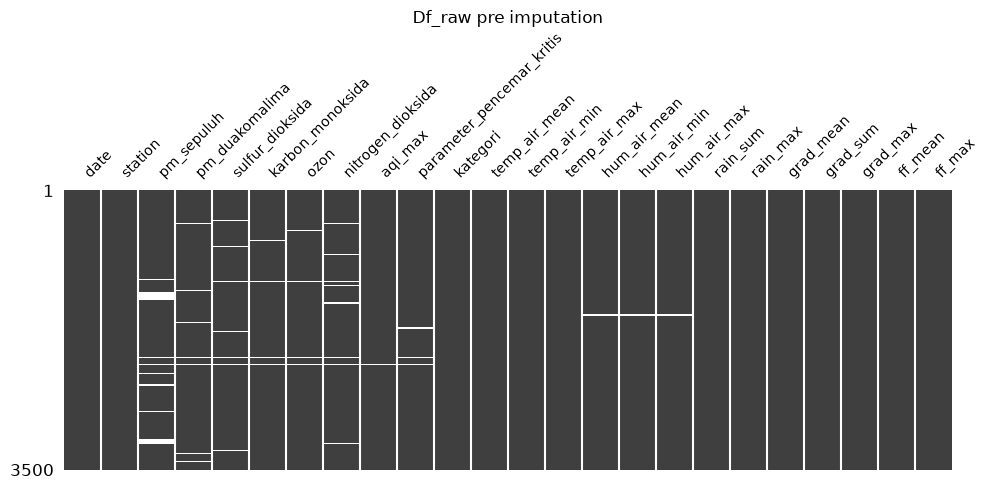

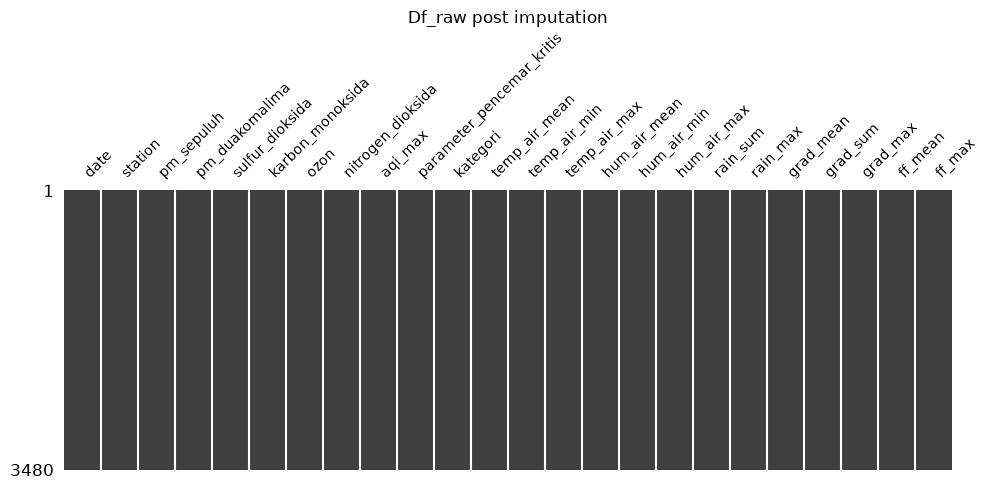

In [16]:
# Missing Values Sanity Check
fig, ax = plt.subplots(figsize=(10, 5))
msno.matrix(df_filtered, ax=ax, sparkline=False, fontsize=10)
ax.set_title("Df_raw pre imputation")
plt.tight_layout()
plt.show()

fig, ax = plt.subplots(figsize=(10, 5))
msno.matrix(df_impute, ax=ax, sparkline=False, fontsize=10)
ax.set_title("Df_raw post imputation")
plt.tight_layout()
plt.show()

### **2.3 Outlier Checking & Handling**


/tmp/ipykernel_22225/3214451416.py:9: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  ax_pre.boxplot(df_pre[col].dropna(), vert=True, showmeans=True)
/tmp/ipykernel_22225/3214451416.py:16: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  ax_post.boxplot(df_post[col].dropna(), vert=True, showmeans=True)
/tmp/ipykernel_22225/3214451416.py:9: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  ax_pre.boxplot(df_pre[col].dropna(), vert=True, showmeans=True)
/tmp/ipykernel_22225/3214451416.py:16: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  ax_post.boxplot(

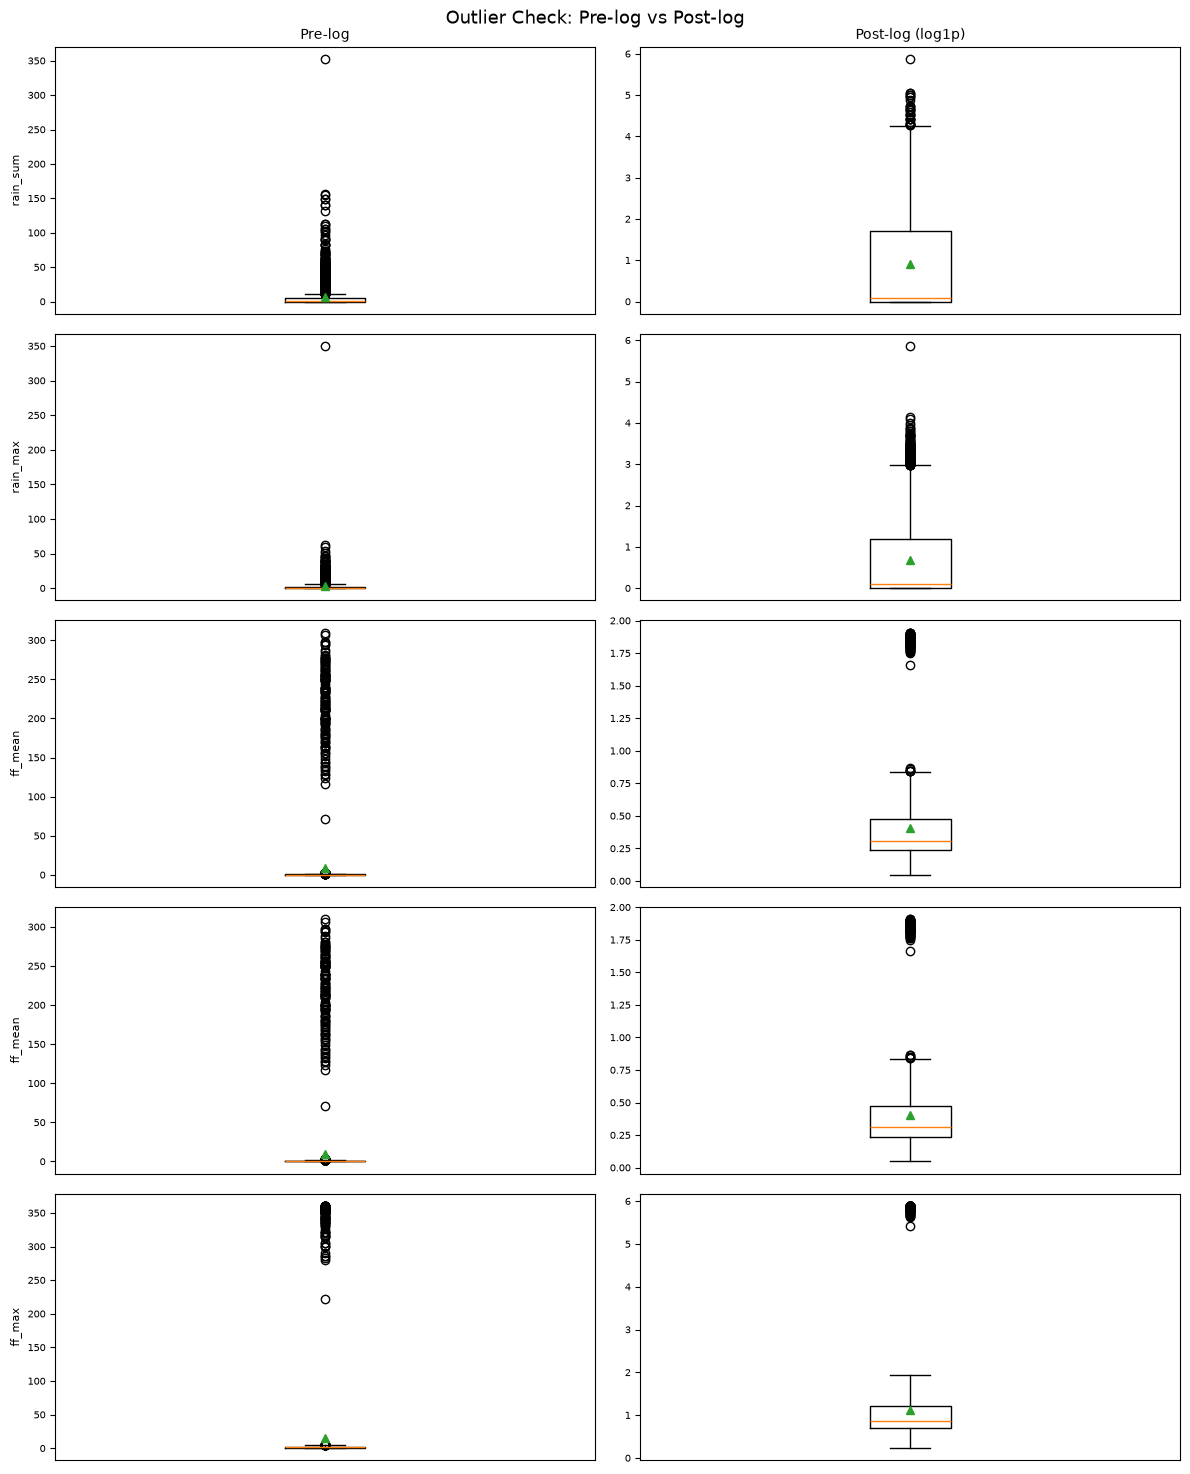

In [18]:
def show_box_plots_compare(df_pre: pd.DataFrame, df_post: pd.DataFrame, num_cols: list[str]):
    n = len(num_cols)
    fig, axes = plt.subplots(n, 2, figsize=(12, n * 3))
    axes = np.atleast_2d(axes)

    for row, col in enumerate(num_cols):
        ax_pre, ax_post = axes[row, 0], axes[row, 1]

        ax_pre.boxplot(df_pre[col].dropna(), vert=True, showmeans=True)
        ax_pre.set_ylabel(col, fontsize=8)
        ax_pre.set_xticks([])
        ax_pre.tick_params(axis="y", labelsize=7)
        if row == 0:
            ax_pre.set_title("Pre-log", fontsize=10)

        ax_post.boxplot(df_post[col].dropna(), vert=True, showmeans=True)
        ax_post.set_xticks([])
        ax_post.tick_params(axis="y", labelsize=7)
        if row == 0:
            ax_post.set_title("Post-log (log1p)", fontsize=10)

    fig.suptitle("Outlier Check: Pre-log vs Post-log", fontsize=13)
    plt.tight_layout()
    plt.show()



df_log = df_impute.copy()

# Skewed variables based on .describe() results
log_columns = ["rain_sum", "rain_max", "ff_mean", "ff_mean", "ff_max"]


for col in log_columns:
    df_log[col] = np.log1p(df_log[col])

show_box_plots_compare(df_impute, df_log, log_columns)

In [20]:
# Outlier Calculations
for col in num_cols:
    q1 = df_log[col].quantile(0.25)
    q3 = df_log[col].quantile(0.75)
    
    iqr = q3 - q1
    
    lower = q1 - 1.5 * iqr
    upper = q3 + 1.5 * iqr

    outlier_counts = ((df_log[col] < lower) | (df_log[col] > upper)).sum()
    outlier_pct = outlier_counts / len(df_log[col]) * 100
    
    print(f"{col}: {outlier_counts} outliers {outlier_pct}")

pm_sepuluh: 15 outliers 0.43103448275862066
pm_duakomalima: 23 outliers 0.6609195402298851
sulfur_dioksida: 1 outliers 0.028735632183908046
karbon_monoksida: 41 outliers 1.1781609195402298
ozon: 170 outliers 4.885057471264368
nitrogen_dioksida: 61 outliers 1.752873563218391
aqi_max: 20 outliers 0.5747126436781609
temp_air_mean: 11 outliers 0.3160919540229885
temp_air_min: 4 outliers 0.11494252873563218
temp_air_max: 112 outliers 3.218390804597701
hum_air_mean: 5 outliers 0.14367816091954022
hum_air_min: 67 outliers 1.9252873563218391
hum_air_max: 2 outliers 0.05747126436781609
rain_sum: 30 outliers 0.8620689655172413
rain_max: 157 outliers 4.511494252873563
grad_mean: 5 outliers 0.14367816091954022
grad_sum: 3 outliers 0.08620689655172414
grad_max: 8 outliers 0.22988505747126436
ff_mean: 143 outliers 4.109195402298851
ff_max: 137 outliers 3.936781609195402
